# Day 36: Veda Technology Business & Service Analytics

**Dataset:** the cleaned Veda Technology tables saved on Day 35
(`datasets/veda_business/cleaned/`)

This notebook is the second of four days in the Veda Technology Business & Service Analytics
project. It continues from the cleaned tables created on Day 35 and covers the training
program performance analysis, the IT service inquiry analysis, the digital service inquiry
analysis, and the customer/service request analysis.

## 1. Import Libraries and Load the Cleaned Tables

In [1]:
import sqlite3
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CLEAN_DIR = Path("../datasets/veda_business/cleaned")

training = pd.read_csv(CLEAN_DIR / "training_enrollments_cleaned.csv", parse_dates=["enrollment_date"])
it_inquiries = pd.read_csv(CLEAN_DIR / "it_service_inquiries_cleaned.csv", parse_dates=["inquiry_date"])
digital_inquiries = pd.read_csv(CLEAN_DIR / "digital_service_inquiries_cleaned.csv", parse_dates=["inquiry_date"])
requests = pd.read_csv(CLEAN_DIR / "service_requests_cleaned.csv", parse_dates=["request_date"])

for name, table in [("training", training), ("it_inquiries", it_inquiries), ("digital_inquiries", digital_inquiries), ("requests", requests)]:
    print(f"{name}: {table.shape[0]:,} rows, {table.shape[1]} columns")

training.head()

training: 1,800 rows, 10 columns
it_inquiries: 1,100 rows, 9 columns
digital_inquiries: 1,300 rows, 9 columns
requests: 3,200 rows, 8 columns


,enrollment_id,enrollment_date,program,mode,lead_source,fee_inr,attendance_pct,final_score,completed,satisfaction_rating
0,T00001,2025-10-01,Cloud Computing,Online,Paid Ads,12800,65.3,21.7,0,4.0
1,T00002,2025-10-01,Python Programming,Offline,Referral,7200,78.0,69.5,1,3.0
2,T00003,2025-10-01,Cybersecurity Basics,Online,Paid Ads,14000,77.0,58.9,1,3.0
3,T00004,2025-10-01,Full Stack Web Development,Hybrid,Social Media,14400,71.4,61.8,1,3.0
4,T00005,2025-10-01,Data Analytics,Offline,Social Media,15000,86.6,69.8,1,3.0


**The gaps from Day 35**

A few columns still have missing values by design, because the gap itself carries meaning,
and they need to be handled carefully in the analysis below.

In [2]:
print("Training: missing satisfaction ratings (students who did not answer the survey):", training["satisfaction_rating"].isna().sum())

no_resolution = requests["resolution_time_hours"].isna()
print("Requests: missing resolution time:", no_resolution.sum(), "| all of them are Open requests:", requests.loc[no_resolution, "status"].eq("Open").all())
print("Requests: missing satisfaction ratings:", requests["satisfaction_rating"].isna().sum())

Training: missing satisfaction ratings (students who did not answer the survey): 101
Requests: missing resolution time: 188 | all of them are Open requests: True
Requests: missing satisfaction ratings: 805


## 2. Training Program Performance Analysis

**Key figures for the year**

In [3]:
training["enroll_month"] = training["enrollment_date"].dt.to_period("M")

training_kpis = pd.Series({
    "Total enrollments": len(training),
    "Total fee revenue (INR)": training["fee_inr"].sum(),
    "Average fee paid (INR)": training["fee_inr"].mean(),
    "Completion rate (%)": training["completed"].mean() * 100,
    "Average attendance (%)": training["attendance_pct"].mean(),
    "Average final score": training["final_score"].mean(),
    "Average satisfaction (1-5)": training["satisfaction_rating"].mean(),
}).round(2)

training_kpis.to_frame("value")

,value
Total enrollments,1800.00
Total fee revenue (INR),24068600.00
Average fee paid (INR),13371.44
Completion rate (%),65.78
Average attendance (%),77.02
Average final score,55.35
Average satisfaction (1-5),3.54


**Performance of each program**

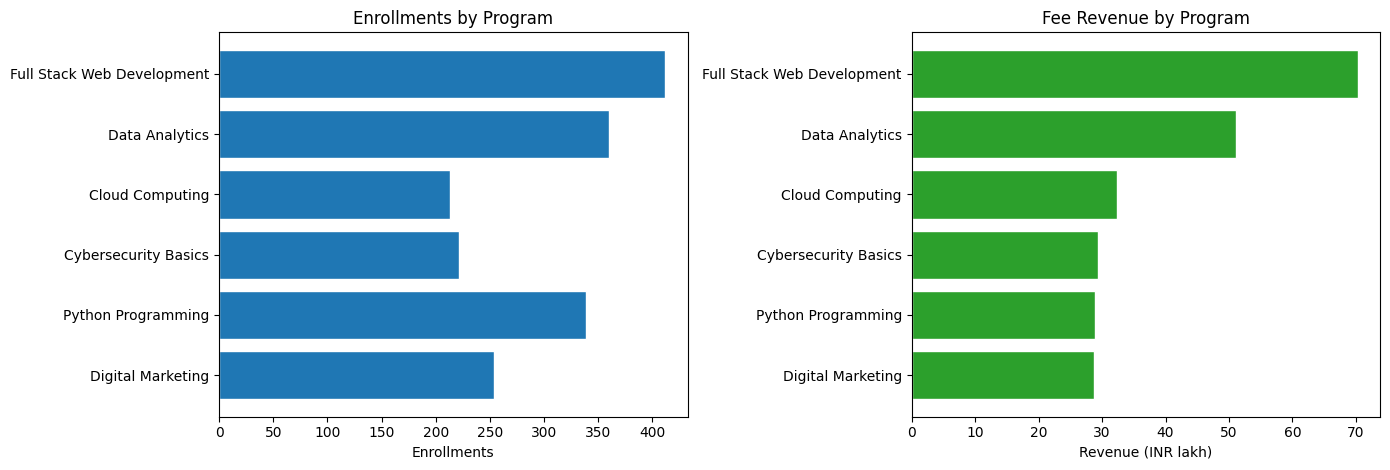

,enrollments,revenue_inr,avg_fee_inr,completion_rate_pct,avg_attendance_pct,avg_score,avg_satisfaction,revenue_share_pct
program,,,,,,,,
Full Stack Web Development,412,7027200,17056.31,64.08,77.51,55.25,3.56,29.20
Data Analytics,360,5118000,14216.67,67.78,76.45,56.48,3.54,21.26
Cloud Computing,213,3228800,15158.69,64.79,75.96,54.23,3.46,13.41
Cybersecurity Basics,222,2940000,13243.24,66.67,76.28,56.22,3.51,12.22
Python Programming,339,2889000,8522.12,65.19,77.24,54.36,3.54,12.00
Digital Marketing,254,2865600,11281.89,66.54,78.26,55.43,3.59,11.91


In [4]:
program_summary = training.groupby("program").agg(
    enrollments=("enrollment_id", "count"),
    revenue_inr=("fee_inr", "sum"),
    avg_fee_inr=("fee_inr", "mean"),
    completion_rate_pct=("completed", "mean"),
    avg_attendance_pct=("attendance_pct", "mean"),
    avg_score=("final_score", "mean"),
    avg_satisfaction=("satisfaction_rating", "mean"),
)
program_summary["completion_rate_pct"] *= 100
program_summary["revenue_share_pct"] = program_summary["revenue_inr"] / program_summary["revenue_inr"].sum() * 100
program_summary = program_summary.round(2).sort_values("revenue_inr", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].barh(program_summary.index[::-1], program_summary["enrollments"][::-1], edgecolor="white")
axes[0].set_title("Enrollments by Program")
axes[0].set_xlabel("Enrollments")
axes[1].barh(program_summary.index[::-1], program_summary["revenue_inr"][::-1] / 100000, edgecolor="white", color="tab:green")
axes[1].set_title("Fee Revenue by Program")
axes[1].set_xlabel("Revenue (INR lakh)")
plt.tight_layout()
plt.show()

program_summary

**Delivery mode and lead source**

In [5]:
def training_summary(column):
    summary = training.groupby(column).agg(
        enrollments=("enrollment_id", "count"), completion_rate_pct=("completed", "mean"),
        avg_attendance_pct=("attendance_pct", "mean"), avg_score=("final_score", "mean"), avg_satisfaction=("satisfaction_rating", "mean"),
    )
    summary["completion_rate_pct"] *= 100
    return summary.round(2).sort_values("enrollments", ascending=False)


mode_summary = training_summary("mode")
source_summary = training_summary("lead_source")

print("By delivery mode")
print(mode_summary)
print("\nBy lead source")
print(source_summary)

By delivery mode
         enrollments  completion_rate_pct  avg_attendance_pct  avg_score  \
mode                                                                       
Online           893                63.72               74.78      54.26   
Hybrid           564                64.72               77.63      55.87   
Offline          343                72.89               81.86      57.34   

         avg_satisfaction  
mode                       
Online               3.57  
Hybrid               3.47  
Offline              3.58  

By lead source
                enrollments  completion_rate_pct  avg_attendance_pct  \
lead_source                                                            
Organic Search          501                68.66               77.28   
Social Media            443                65.91               76.97   
Referral                248                61.29               77.51   
Direct                  243                66.67               76.89   
Paid Ads      

**Observation:** the 1,800 training enrollments brought in INR 24.1 million in fees, an
average of INR 13,371 per student, with a completion rate of 65.8%, average attendance of
77.0%, an average final score of 55.4, and an average satisfaction rating of 3.54 out of 5.
Full Stack Web Development is the clear revenue leader (29.2% of fee revenue from 22.9% of
enrollments), followed by Data Analytics (21.3%). Enrollment numbers and revenue tell
different stories for the cheaper programs: Python Programming is the third most popular
program (339 enrollments) but, at an average fee of INR 8,522, it brings in only 12.0% of
revenue, and Digital Marketing has the smallest revenue share (11.9%). The programs
themselves perform alike: completion rates only range from 64.1% to 67.8% and satisfaction
from 3.46 to 3.59. Delivery mode matters more. Offline students complete at 72.9%, compared
to 64.7% for hybrid and 63.7% for online, and they attend more (81.9% versus 74.8% online)
and score higher (57.3 versus 54.3), yet only 19% of students take offline classes while 50%
study online. The lead sources differ little (completion rates from 61.3% to 68.7%, lowest
for Referral), and with a few hundred students per source those gaps should not be
over-read.

**What drives completion and scores? Attendance, score, and satisfaction**

Correlation between attendance and final score: 0.26
Correlation between final score and satisfaction: 0.18


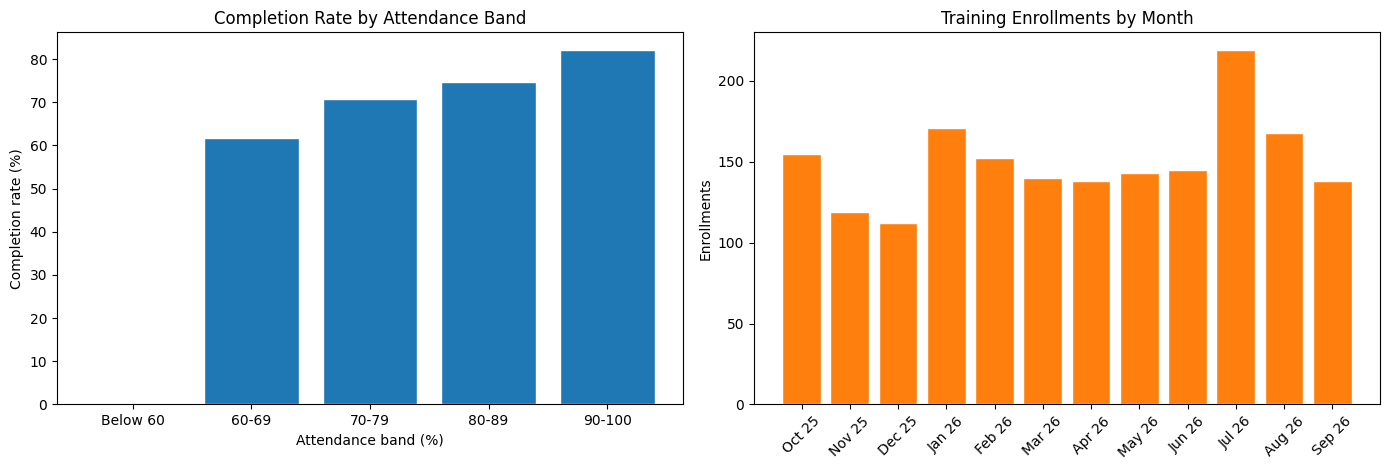

,enrollments,completion_rate_pct,avg_score
attendance_pct,,,
Below 60,150,0.0,48.8
60-69,350,61.7,51.3
70-79,556,70.7,54.8
80-89,482,74.7,57.8
90-100,262,82.1,61.3


In [6]:
attendance_band = pd.cut(
    training["attendance_pct"], bins=[0, 60, 70, 80, 90, 100.01],
    labels=["Below 60", "60-69", "70-79", "80-89", "90-100"], right=False,
)
band_summary = training.groupby(attendance_band, observed=True).agg(
    enrollments=("enrollment_id", "count"), completion_rate_pct=("completed", "mean"), avg_score=("final_score", "mean"),
)
band_summary["completion_rate_pct"] *= 100
band_summary = band_summary.round(1)

corr_attendance_score = training["attendance_pct"].corr(training["final_score"])
corr_score_satisfaction = training["final_score"].corr(training["satisfaction_rating"])
print(f"Correlation between attendance and final score: {corr_attendance_score:.2f}")
print(f"Correlation between final score and satisfaction: {corr_score_satisfaction:.2f}")

monthly_training = training.groupby("enroll_month").agg(enrollments=("enrollment_id", "count"), revenue_inr=("fee_inr", "sum"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar(band_summary.index.astype(str), band_summary["completion_rate_pct"], edgecolor="white")
axes[0].set_title("Completion Rate by Attendance Band")
axes[0].set_xlabel("Attendance band (%)")
axes[0].set_ylabel("Completion rate (%)")
axes[1].bar(monthly_training.index.strftime("%b %y"), monthly_training["enrollments"], edgecolor="white", color="tab:orange")
axes[1].set_title("Training Enrollments by Month")
axes[1].set_ylabel("Enrollments")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

band_summary

**Observation:** attendance is the clearest warning sign. None of the 150 students who
attended less than 60% of the sessions completed their program, and the completion rate
climbs with every attendance band, up to 82.1% for students at 90% or above, while the
average final score rises from 48.8 to 61.3. Across all students the correlation between
attendance and final score is 0.26, a weak-to-moderate positive link, and the correlation
between final score and satisfaction is 0.18, so students who do better are only slightly
happier. Enrollments follow the seasonal pattern built into the simulation, peaking in July
2026 (219) and dropping to 112 in December 2025. Because the attendance and completion rules
were part of the simulation, these links show how to read the analysis, not how real
students behave.

## 3. IT Service Inquiry Analysis

The IT and digital inquiry tables have the same structure, so one set of functions analyzes
both. An inquiry counts as **converted** when its status is `Converted`, and the response
time is grouped into three bands to see whether speed affects the outcome.

**Helper functions shared by the IT and digital inquiry analyses**

In [7]:
def prepare_inquiries(data):
    data = data.copy()
    data["is_converted"] = (data["status"] == "Converted").astype(int)
    data["response_band"] = pd.cut(
        data["response_time_hours"], bins=[0, 4, 24, np.inf],
        labels=["Within 4 hours", "4 to 24 hours", "Over 24 hours"],
    )
    data["inquiry_month"] = data["inquiry_date"].dt.to_period("M")
    return data


def inquiry_kpis(data):
    converted = data[data["is_converted"] == 1]
    return pd.Series({
        "Total inquiries": len(data),
        "Converted": len(converted),
        "Conversion rate (%)": data["is_converted"].mean() * 100,
        "Lost (%)": (data["status"] == "Lost").mean() * 100,
        "Still in progress (%)": (data["status"] == "In Progress").mean() * 100,
        "Average budget (INR)": data["budget_inr"].mean(),
        "Total deal value (INR)": data["deal_value_inr"].sum(),
        "Average deal value (INR)": converted["deal_value_inr"].mean(),
        "Average response time (hours)": data["response_time_hours"].mean(),
    }).round(2)


def inquiry_summary(data, column):
    summary = data.groupby(column, observed=True).agg(
        inquiries=("inquiry_id", "count"), converted=("is_converted", "sum"), conversion_rate_pct=("is_converted", "mean"),
        avg_budget_inr=("budget_inr", "mean"), deal_value_inr=("deal_value_inr", "sum"),
    )
    summary["conversion_rate_pct"] *= 100
    summary["share_of_inquiries_pct"] = summary["inquiries"] / len(data) * 100
    return summary.round(2)


def plot_inquiries(data, title):
    by_service = inquiry_summary(data, "service_type").sort_values("conversion_rate_pct")
    by_channel = inquiry_summary(data, "channel").sort_values("conversion_rate_pct")
    by_response = inquiry_summary(data, "response_band")

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    axes[0].barh(by_service.index, by_service["conversion_rate_pct"], edgecolor="white")
    axes[0].set_title("Conversion Rate by Service")
    axes[0].set_xlabel("Conversion rate (%)")
    axes[1].barh(by_channel.index, by_channel["conversion_rate_pct"], edgecolor="white", color="tab:green")
    axes[1].set_title("Conversion Rate by Channel")
    axes[1].set_xlabel("Conversion rate (%)")
    axes[2].bar(by_response.index.astype(str), by_response["conversion_rate_pct"], edgecolor="white", color="tab:orange")
    axes[2].set_title("Conversion Rate by Response Time")
    axes[2].set_ylabel("Conversion rate (%)")
    axes[2].tick_params(axis="x", rotation=20)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

**Key figures for IT service inquiries**

In [8]:
it = prepare_inquiries(it_inquiries)
it_kpis = inquiry_kpis(it)
it_kpis.to_frame("value")

,value
Total inquiries,1.100000e+03
Converted,5.030000e+02
Conversion rate (%),4.573000e+01
Lost (%),2.991000e+01
Still in progress (%),2.436000e+01
Average budget (INR),4.811055e+05
Total deal value (INR),2.057160e+08
Average deal value (INR),4.089781e+05
Average response time (hours),8.580000e+00


**Demand and conversion by service, client type, channel, and response time**

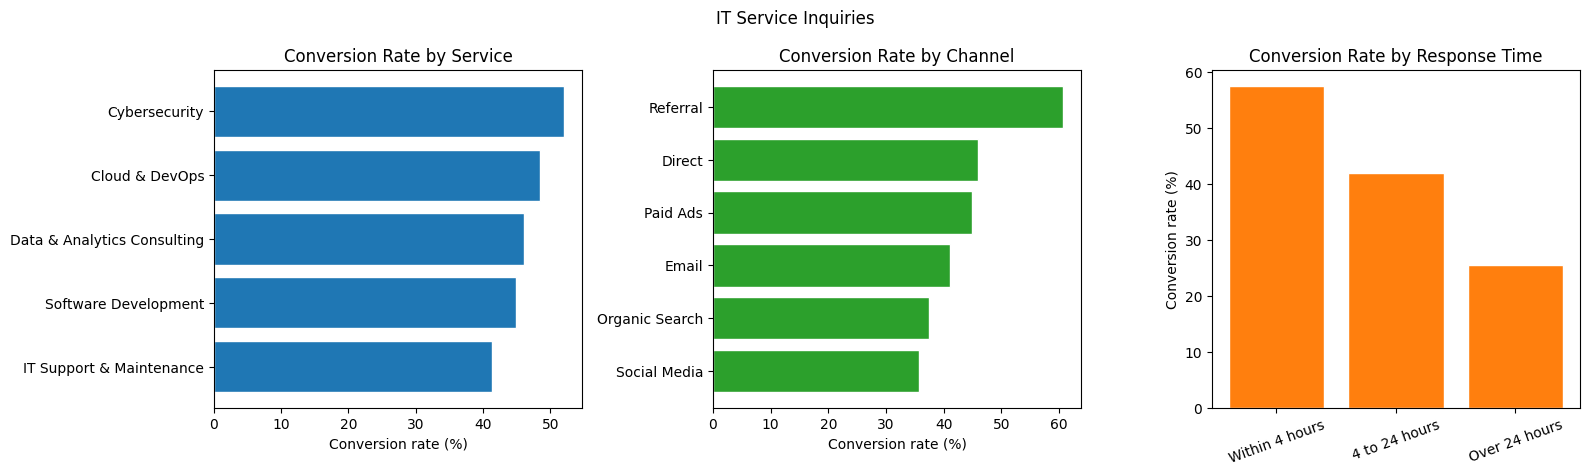

By service
                             inquiries  converted  conversion_rate_pct  \
service_type                                                             
Software Development               310        139                44.84   
IT Support & Maintenance           278        115                41.37   
Cloud & DevOps                     190         92                48.42   
Data & Analytics Consulting        180         83                46.11   
Cybersecurity                      142         74                52.11   

                             avg_budget_inr  deal_value_inr  \
service_type                                                  
Software Development              515925.81        61166000   
IT Support & Maintenance          399347.12        37138000   
Cloud & DevOps                    501807.89        40821000   
Data & Analytics Consulting       370872.22        25686000   
Cybersecurity                     677183.10        40905000   

                            

In [9]:
it_by_service = inquiry_summary(it, "service_type").sort_values("inquiries", ascending=False)
it_by_client = inquiry_summary(it, "client_type").sort_values("inquiries", ascending=False)
it_by_channel = inquiry_summary(it, "channel").sort_values("inquiries", ascending=False)
it_by_response = inquiry_summary(it, "response_band")

plot_inquiries(it, "IT Service Inquiries")

print("By service")
print(it_by_service)
print("\nBy client type")
print(it_by_client)
print("\nBy channel")
print(it_by_channel)
print("\nBy response time")
print(it_by_response)

**Observation:** Veda Technology received 1,100 IT service inquiries and converted 45.7% of
them into deals, while 29.9% were lost and 24.4% are still in progress. The average budget
is INR 481,105, the deals add up to INR 205.7 million, and the average response time is 8.6
hours. Speed shows a clear effect: inquiries answered within 4 hours converted at 57.4%,
those answered in 4 to 24 hours at 41.9%, and the 51 inquiries that waited more than a day
at only 25.5% (a small group, only 4.6% of inquiries, so treat that figure with care). The
channel matters too: Referral inquiries convert at 60.7%, far above the 45.7% average, while
Organic Search, the largest source (27.4% of inquiries), converts at only 37.4% and Social
Media is lowest at 35.8%. By service, Software Development gets the most inquiries (310) and
the most deal value (29.7% of the total), while Cybersecurity converts best (52.1%) and has
the highest average budget (INR 677K). By client type, SMEs send the most inquiries (33.6%)
and convert best (50.3%), but Enterprise clients are the biggest source of money: they send
only 12.7% of inquiries and account for 39.0% of deal value, while Individuals send 12.8% of
inquiries and only 1.2% of the value. Inquiries peak in March 2026 (117), the end of the
fiscal year in India.

## 4. Digital Service Inquiry Analysis

**Key figures for digital service inquiries**

In [10]:
digital = prepare_inquiries(digital_inquiries)
digital_kpis = inquiry_kpis(digital)
digital_kpis.to_frame("value")

,value
Total inquiries,1300.00
Converted,561.00
Conversion rate (%),43.15
Lost (%),31.00
Still in progress (%),25.85
Average budget (INR),69706.54
Total deal value (INR),35645000.00
Average deal value (INR),63538.32
Average response time (hours),7.97


**Demand and conversion by service, client type, channel, and response time**

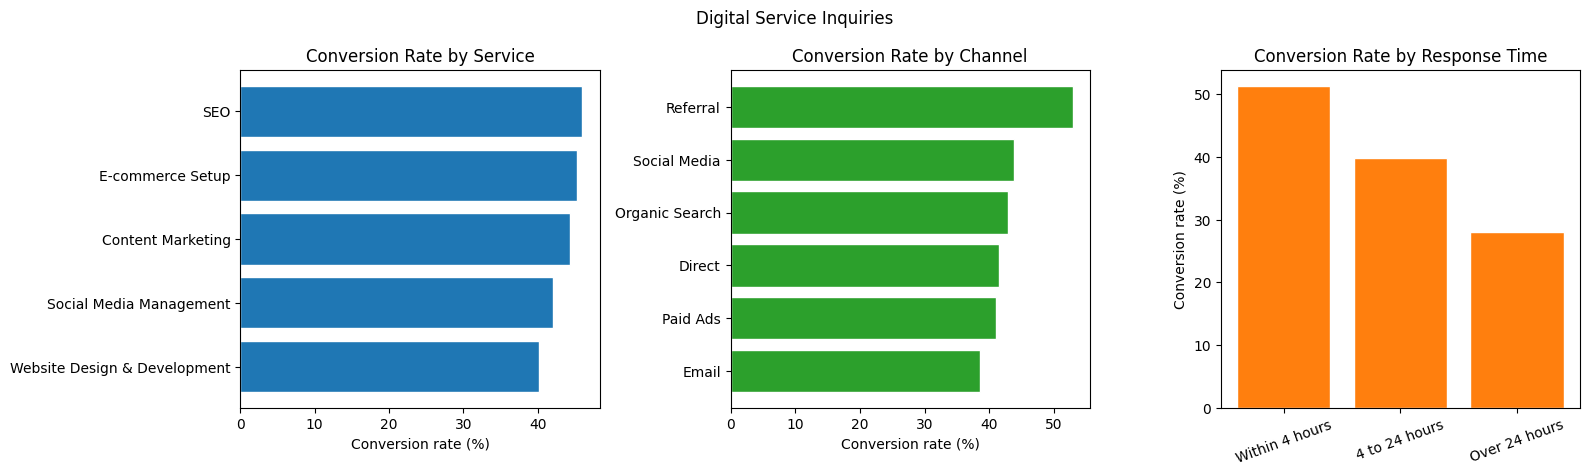

By service
                              inquiries  converted  conversion_rate_pct  \
service_type                                                              
Website Design & Development        361        145                40.17   
Social Media Management             288        121                42.01   
SEO                                 265        122                46.04   
Content Marketing                   205         91                44.39   
E-commerce Setup                    181         82                45.30   

                              avg_budget_inr  deal_value_inr  \
service_type                                                   
Website Design & Development        71034.63         8953000   
Social Media Management             70149.31         7296000   
SEO                                 69769.81         8259000   
Content Marketing                   71619.51         6545000   
E-commerce Setup                    64093.92         4592000   

              

In [11]:
digital_by_service = inquiry_summary(digital, "service_type").sort_values("inquiries", ascending=False)
digital_by_client = inquiry_summary(digital, "client_type").sort_values("inquiries", ascending=False)
digital_by_channel = inquiry_summary(digital, "channel").sort_values("inquiries", ascending=False)
digital_by_response = inquiry_summary(digital, "response_band")

plot_inquiries(digital, "Digital Service Inquiries")

print("By service")
print(digital_by_service)
print("\nBy client type")
print(digital_by_client)
print("\nBy channel")
print(digital_by_channel)
print("\nBy response time")
print(digital_by_response)

**IT versus digital inquiries side by side, and how they trend by month**

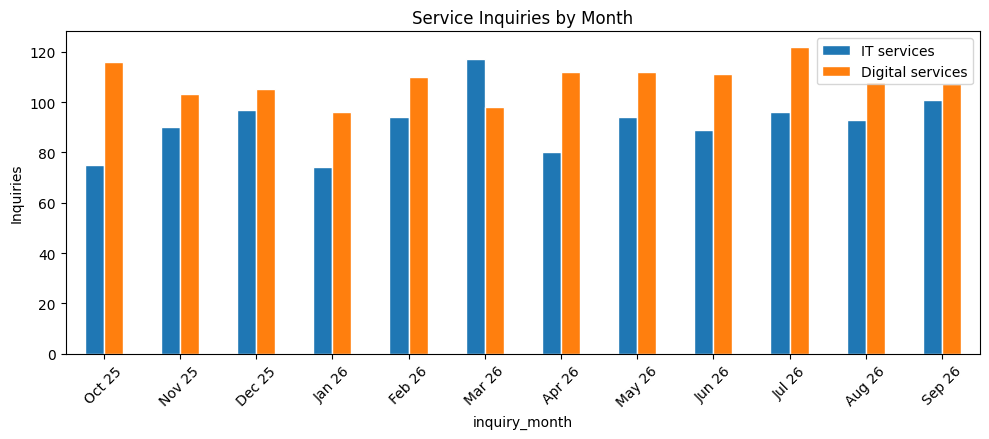

,IT services,Digital services
Total inquiries,1.100000e+03,1300.00
Converted,5.030000e+02,561.00
Conversion rate (%),4.573000e+01,43.15
Lost (%),2.991000e+01,31.00
Still in progress (%),2.436000e+01,25.85
Average budget (INR),4.811055e+05,69706.54
Total deal value (INR),2.057160e+08,35645000.00
Average deal value (INR),4.089781e+05,63538.32
Average response time (hours),8.580000e+00,7.97


In [12]:
side_by_side = pd.DataFrame({"IT services": it_kpis, "Digital services": digital_kpis})

monthly_inquiries = pd.DataFrame({
    "IT services": it.groupby("inquiry_month").size(),
    "Digital services": digital.groupby("inquiry_month").size(),
})

monthly_inquiries.index = monthly_inquiries.index.strftime("%b %y")
monthly_inquiries.plot(kind="bar", figsize=(10, 4.5), edgecolor="white")
plt.ylabel("Inquiries")
plt.title("Service Inquiries by Month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

side_by_side

**Observation:** there were 1,300 digital service inquiries, with a conversion rate of 43.1%
(31.0% lost and 25.9% still in progress), an average budget of INR 70K, and INR 35.6 million
in total deal value. The patterns echo the IT inquiries: response speed matters (within 4
hours: 51.3%, 4 to 24 hours: 39.9%, over 24 hours: 28.0%, though only 50 inquiries waited
that long), Referral is the best channel (52.9%), and Email is the weakest (38.6%). Website
Design & Development draws the most inquiries (361, 27.8%) but converts the least (40.2%),
while SEO converts best (46.0%). Small businesses are 45% of the inquiries, Startups have
the largest budgets (INR 107K on average), and Individuals and freelancers have the smallest
(INR 22K). Compared side by side, the two lines are alike in conversion (45.7% for IT versus
43.1% for digital) and response time (8.6 versus 8.0 hours), but very different in value: IT
deals bring in about 5.8 times the total deal value of digital deals, with an average deal
about 6.4 times larger, even though digital services get more inquiries. Digital inquiries
are also steadier month to month (96 to 122), while IT inquiries have a visible spike in
March.

## 5. Customer and Service Request Analysis

**Key figures for the year**

A request that is still `Open` has no resolution time yet, so resolution-time figures use
only requests that have been resolved or escalated.

In [13]:
requests["is_escalated"] = (requests["status"] == "Escalated").astype(int)
requests["is_open"] = (requests["status"] == "Open").astype(int)
requests["request_month"] = requests["request_date"].dt.to_period("M")
closed = requests[requests["is_open"] == 0]

request_kpis = pd.Series({
    "Total requests": len(requests),
    "Resolved (%)": (requests["status"] == "Resolved").mean() * 100,
    "Escalated (%)": requests["is_escalated"].mean() * 100,
    "Still open (%)": requests["is_open"].mean() * 100,
    "Average resolution time (hours)": closed["resolution_time_hours"].mean(),
    "Median resolution time (hours)": closed["resolution_time_hours"].median(),
    "Average satisfaction (1-5)": requests["satisfaction_rating"].mean(),
}).round(2)

request_kpis.to_frame("value")

,value
Total requests,3200.00
Resolved (%),84.56
Escalated (%),9.56
Still open (%),5.88
Average resolution time (hours),22.72
Median resolution time (hours),16.60
Average satisfaction (1-5),3.90


**Where requests come from and what they are about**

In [14]:
def request_summary(column):
    summary = requests.groupby(column).agg(
        requests=("request_id", "count"), escalation_rate_pct=("is_escalated", "mean"), open_rate_pct=("is_open", "mean"),
        avg_satisfaction=("satisfaction_rating", "mean"),
    )
    summary["escalation_rate_pct"] *= 100
    summary["open_rate_pct"] *= 100
    summary["avg_resolution_hours"] = closed.groupby(column)["resolution_time_hours"].mean()
    summary["share_of_requests_pct"] = summary["requests"] / len(requests) * 100
    return summary.round(2).sort_values("requests", ascending=False)


area_summary = request_summary("service_area")
type_summary = request_summary("request_type")

print("By service area")
print(area_summary)
print("\nBy request type")
print(type_summary)

By service area
                    requests  escalation_rate_pct  open_rate_pct  \
service_area                                                       
IT Services              993                 9.97           5.34   
Training Programs        860                 9.77           7.09   
Internship Program       682                 9.53           5.87   
Digital Services         665                 8.72           5.11   

                    avg_satisfaction  avg_resolution_hours  \
service_area                                                 
IT Services                     3.92                 22.42   
Training Programs               3.93                 22.17   
Internship Program              3.88                 22.45   
Digital Services                3.83                 24.12   

                    share_of_requests_pct  
service_area                               
IT Services                         31.03  
Training Programs                   26.88  
Internship Program        

**Priority, resolution time, and a service-level target**

The data has no official service-level targets, so these targets are an **assumption** used
to illustrate the analysis: Critical within 8 hours, High within 24, Medium within 48, and
Low within 72.

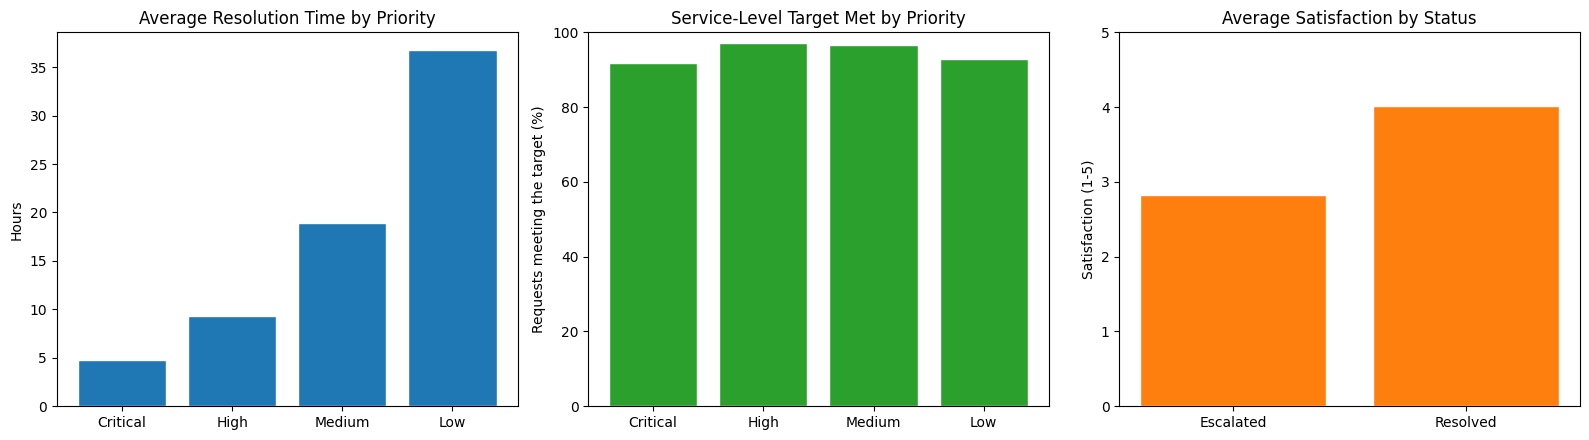

          closed_requests  avg_resolution_hours  median_resolution_hours  \
priority                                                                   
Critical              170                  4.81                      4.2   
High                  543                  9.33                      8.0   
Medium               1229                 18.89                     15.8   
Low                  1070                 36.75                     31.9   

          sla_met_pct  share_of_requests_pct  
priority                                      
Critical        91.76                   5.81  
High            97.05                  18.00  
Medium          96.66                  40.88  
Low             92.90                  35.31  

           count  mean
status                
Escalated    242  2.83
Resolved    2153  4.02


In [15]:
SLA_HOURS = {"Critical": 8, "High": 24, "Medium": 48, "Low": 72}
priority_order = ["Critical", "High", "Medium", "Low"]

closed = closed.copy()
closed["sla_met"] = closed["resolution_time_hours"] <= closed["priority"].map(SLA_HOURS)

priority_summary = closed.groupby("priority").agg(
    closed_requests=("request_id", "count"),
    avg_resolution_hours=("resolution_time_hours", "mean"),
    median_resolution_hours=("resolution_time_hours", "median"),
    sla_met_pct=("sla_met", "mean"),
).reindex(priority_order)
priority_summary["sla_met_pct"] *= 100
priority_summary["share_of_requests_pct"] = requests["priority"].value_counts(normalize=True).reindex(priority_order) * 100
priority_summary = priority_summary.round(2)

status_satisfaction = requests.groupby("status")["satisfaction_rating"].agg(["count", "mean"]).round(2).drop("Open")  # open requests cannot have a rating yet

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].bar(priority_summary.index, priority_summary["avg_resolution_hours"], edgecolor="white")
axes[0].set_title("Average Resolution Time by Priority")
axes[0].set_ylabel("Hours")
axes[1].bar(priority_summary.index, priority_summary["sla_met_pct"], edgecolor="white", color="tab:green")
axes[1].set_title("Service-Level Target Met by Priority")
axes[1].set_ylabel("Requests meeting the target (%)")
axes[1].set_ylim(0, 100)
axes[2].bar(status_satisfaction.index, status_satisfaction["mean"], edgecolor="white", color="tab:orange")
axes[2].set_title("Average Satisfaction by Status")
axes[2].set_ylabel("Satisfaction (1-5)")
axes[2].set_ylim(0, 5)
plt.tight_layout()
plt.show()

print(priority_summary)
print()
print(status_satisfaction)

**Observation:** of the 3,200 service requests, 84.6% were resolved, 9.6% were escalated,
and 5.9% are still open, with an average resolution time of 22.7 hours (median 16.6) and an
average satisfaction of 3.90 out of 5. IT Services generates the most requests (31.0%),
followed by Training Programs (26.9%), but the service areas behave alike: escalation rates
only range from 8.7% to 10.0%, and Support Ticket is the most common request type (44.0%).
Two details stand out: Training Programs has the highest share of requests still open
(7.1%), and Billing Queries are the slowest to resolve (26.6 hours, against at most 23.2 for
the other types) and the most likely to stay open (8.1%). Satisfaction is nearly the same
across request types (3.84 to 3.98), but it depends strongly on how a request ends: resolved
requests average 4.02 and escalated requests only 2.83. Priority works as intended, with
average resolution times of 4.8 hours for Critical, 9.3 for High, 18.9 for Medium, and 36.8
for Low. Against the assumed service-level targets, High (97.0%) and Medium (96.7%) requests
meet their target almost every time, while Critical requests have the lowest compliance
(91.8%), because their target is the tightest compared with their typical resolution time
(about 1.9 times the median, versus 3.0 times for High and 3.0 for Medium), and Low requests
follow at 92.9%, which makes the Critical queue the first place to look for improvement. The
SQL query returns the same counts and averages as pandas.

**Request volume and escalation by month**

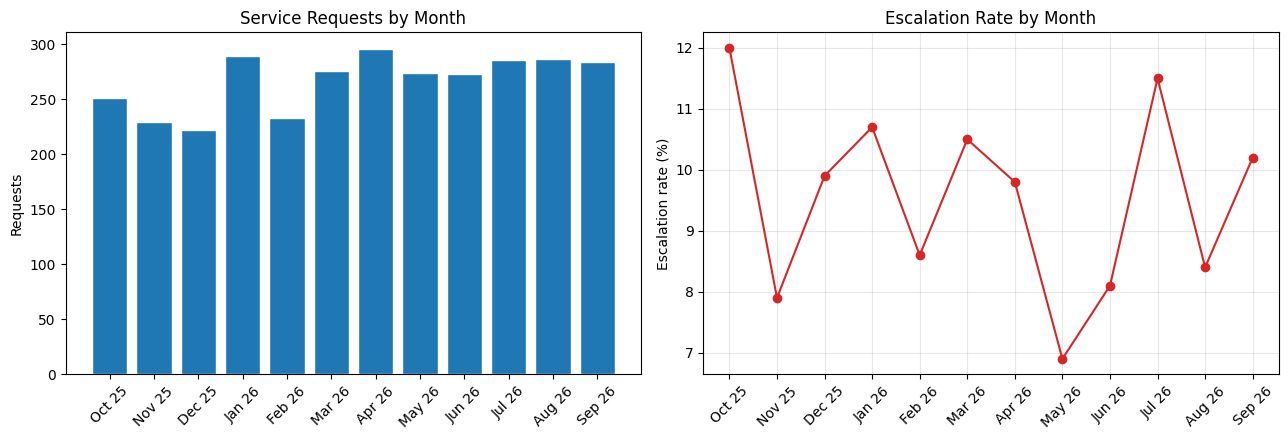

,requests,escalated,escalation_rate_pct
request_month,,,
2025-10,251,30,12.0
2025-11,229,18,7.9
2025-12,222,22,9.9
2026-01,289,31,10.7
2026-02,233,20,8.6
2026-03,276,29,10.5
2026-04,296,29,9.8
2026-05,274,19,6.9
2026-06,273,22,8.1


In [16]:
monthly_requests = requests.groupby("request_month").agg(requests=("request_id", "count"), escalated=("is_escalated", "sum"))
monthly_requests["escalation_rate_pct"] = (monthly_requests["escalated"] / monthly_requests["requests"] * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(monthly_requests.index.strftime("%b %y"), monthly_requests["requests"], edgecolor="white")
axes[0].set_title("Service Requests by Month")
axes[0].set_ylabel("Requests")
axes[0].tick_params(axis="x", rotation=45)
axes[1].plot(monthly_requests.index.strftime("%b %y"), monthly_requests["escalation_rate_pct"], marker="o", color="tab:red")
axes[1].set_title("Escalation Rate by Month")
axes[1].set_ylabel("Escalation rate (%)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

monthly_requests

**Observation:** the monthly volume of requests ranges from 222 to 296 and grows over the
year, with 1,700 requests in the second half compared to 1,500 in the first, an increase of
about 13%. The escalation rate moves between 6.9% (May 2026) and 12.0% (October 2025)
without a clear trend, so growth in volume has not (yet) made escalations more common.

**The same question in SQL**

The average resolution time by priority is calculated again with SQL on an in-memory SQLite
database and compared with the pandas result.

In [17]:
conn = sqlite3.connect(":memory:")
requests[["request_id", "priority", "status", "resolution_time_hours"]].to_sql("service_requests", conn, index=False)

query = '''
SELECT priority,
       COUNT(*) AS closed_requests,
       ROUND(AVG(resolution_time_hours), 2) AS avg_resolution_hours
FROM service_requests
WHERE status <> 'Open'
GROUP BY priority;
'''
sql_result = pd.read_sql_query(query, conn)
conn.close()

check = sql_result.merge(priority_summary.reset_index(), on="priority", suffixes=("_sql", "_pandas"))
print("SQL matches pandas:",
      (check["closed_requests_sql"] == check["closed_requests_pandas"]).all()
      and np.allclose(check["avg_resolution_hours_sql"], check["avg_resolution_hours_pandas"], atol=0.01))
sql_result.set_index("priority").reindex(priority_order)

SQL matches pandas: True


,closed_requests,avg_resolution_hours
priority,,
Critical,170,4.81
High,543,9.33
Medium,1229,18.89
Low,1070,36.75


## Outcome

This notebook continued the Veda Technology Business & Service Analytics project from the
cleaned tables saved on Day 35. The training analysis found INR 24.1 million in fee revenue
led by Full Stack Web Development, a 65.8% completion rate that is similar across programs
but higher for offline students (72.9% versus 63.7% online), and a clear attendance warning
sign: no student below 60% attendance completed. The IT and digital inquiry analyses showed
conversion rates of 45.7% and 43.1%, a consistent link between fast responses and
conversion, Referral as the best channel for both, and a large value gap, with IT deals
worth about 5.8 times the total value of digital deals and Enterprise clients providing 39%
of IT deal value from 13% of the inquiries. The service request analysis showed that 84.6%
of 3,200 requests were resolved, that escalated requests leave customers much less satisfied
(2.83 versus 4.02), that Billing Queries are slowest to resolve, and that Critical requests
have the lowest service-level compliance (91.8%) under the assumed targets. Because the data
is simulated, these findings reflect the assumptions built into it and practice the analysis
workflow instead of describing the real company. The cleaned tables are unchanged, ready for
the marketing, segmentation, service demand, and dashboard work on Day 37.